In [9]:
#Import Statements
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
)

RANDOM_STATE = 42

In [ ]:
#Loading the AAPL Dataset
DATA_PATH = Path("../data/raw/AAPL_daily_raw.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("data/raw/AAPL_daily_raw.csv")

df = pd.read_csv(DATA_PATH, index_col=0)

df.index = pd.to_datetime(
    df.index.astype(str).str.slice(0, 19),
    errors="raise",
)

df = df.sort_index()
df.index.name = "Date"

print("Shape:", df.shape)
print("Date range:", df.index.min().date(), "to", df.index.max().date())
display(df.head())

Shape: (2766, 9)
Date range: 2015-01-02 to 2025-12-31


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,daily_return
Date,,,,,,,,,
2015-01-02,27.847500,27.860001,26.837500,27.332500,24.171755,212818400,0.0,0.0,NaN
2015-01-05,27.072500,27.162500,26.352501,26.562500,23.490799,257142000,0.0,0.0,-0.028172
2015-01-06,26.635000,26.857500,26.157499,26.565001,23.493013,263188400,0.0,0.0,0.000094
2015-01-07,26.799999,27.049999,26.674999,26.937500,23.822430,160423600,0.0,0.0,0.014022
2015-01-08,27.307501,28.037500,27.174999,27.972500,24.737757,237458000,0.0,0.0,0.038423


In [ ]:
#Building Features and Traget
FEATURES = [
    "return_1d",
    "return_5d",
    "return_10d",
    "price_to_sma20",
    "price_to_sma50",
    "volatility_20d",
    "momentum_10d",
    "relative_volume",
]

df["return_1d"] = df["Adj Close"].pct_change(1)
df["return_5d"] = df["Adj Close"].pct_change(5)
df["return_10d"] = df["Adj Close"].pct_change(10)

df["sma20"] = df["Adj Close"].rolling(20).mean()
df["sma50"] = df["Adj Close"].rolling(50).mean()

df["price_to_sma20"] = df["Adj Close"] / df["sma20"] - 1
df["price_to_sma50"] = df["Adj Close"] / df["sma50"] - 1

df["volatility_20d"] = df["return_1d"].rolling(20).std()
df["momentum_10d"] = df["Adj Close"].pct_change(10)
df["relative_volume"] = df["Volume"] / df["Volume"].rolling(20).mean()

# Label: will the next trading day's adjusted close be higher?
df["future_return_1d"] = (
    df["Adj Close"].shift(-1) / df["Adj Close"] - 1
)

df["target_up"] = (df["future_return_1d"] > 0).astype(int)

model_df = df[
    FEATURES + ["future_return_1d", "target_up"]
].dropna().copy()

X = model_df[FEATURES]
y = model_df["target_up"]

print("Rows:", len(model_df))
print("\nClass distribution:")
print(y.value_counts().sort_index().rename(index={0: "DOWN", 1: "UP"}))

assert "future_return_1d" not in X.columns
assert X.index.is_monotonic_increasing

Rows: 2716

Class distribution:
target_up
DOWN    1278
UP      1438
Name: count, dtype: int64


In [10]:
#Chronologically Splitting the dataset
n = len(model_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_idx = np.arange(0, train_end - 1)
val_idx = np.arange(train_end, val_end - 1)
test_idx = np.arange(val_end, n)

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

for name, X_part in [
    ("Train", X_train),
    ("Validation", X_val),
    ("Test", X_test),
]:
    print(
        f"{name}: {X_part.index.min().date()} to "
        f"{X_part.index.max().date()} | rows={len(X_part)}"
    )

assert X_train.index.max() < X_val.index.min()
assert X_val.index.max() < X_test.index.min()

Train: 2015-03-16 to 2022-09-28 | rows=1900
Validation: 2022-09-30 to 2024-05-13 | rows=406
Test: 2024-05-15 to 2025-12-30 | rows=408


In [11]:
#Tuning Gradient Boosting Hyperparameters
# learning_rate: 0.03, 0.05, 0.1
# n_estimators: 100, 200
# max_depth: 1, 2


from sklearn.metrics import log_loss

tuning_results = []
tuned_models = {}

for learning_rate in [0.03, 0.05, 0.1]:
    for n_estimators in [100, 200]:
        for max_depth in [1, 2]:

            config_name = (
                f"lr={learning_rate}, "
                f"trees={n_estimators}, "
                f"depth={max_depth}"
            )

            model = GradientBoostingClassifier(
                learning_rate=learning_rate,
                n_estimators=n_estimators,
                max_depth=max_depth,
                min_samples_leaf=20,
                subsample=1.0,
                random_state=RANDOM_STATE,
            )

            model.fit(X_train, y_train)

            train_pred = model.predict(X_train)
            val_pred = model.predict(X_val)
            val_proba = model.predict_proba(X_val)[:, 1]

            tuning_results.append({
                "config": config_name,
                "learning_rate": learning_rate,
                "n_estimators": n_estimators,
                "max_depth": max_depth,
                "train_balanced_accuracy": balanced_accuracy_score(
                    y_train, train_pred
                ),
                "val_balanced_accuracy": balanced_accuracy_score(
                    y_val, val_pred
                ),
                "val_macro_f1": f1_score(
                    y_val, val_pred,
                    average="macro",
                    zero_division=0,
                ),
                "val_log_loss": log_loss(y_val, val_proba),
            })

            tuned_models[config_name] = model

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    ["val_balanced_accuracy", "val_macro_f1"],
    ascending=False,
)

display(tuning_df.round(4))

,config,learning_rate,n_estimators,max_depth,train_balanced_accuracy,val_balanced_accuracy,val_macro_f1,val_log_loss
6,"lr=0.05, trees=200, depth=1",0.05,200,1,0.5648,0.5304,0.5007,0.6945
8,"lr=0.1, trees=100, depth=1",0.10,100,1,0.5649,0.5304,0.5007,0.6947
3,"lr=0.03, trees=200, depth=2",0.03,200,2,0.6136,0.5267,0.5051,0.6988
5,"lr=0.05, trees=100, depth=2",0.05,100,2,0.6088,0.5238,0.4992,0.6967
9,"lr=0.1, trees=100, depth=2",0.10,100,2,0.6435,0.5233,0.5101,0.7049
0,"lr=0.03, trees=100, depth=1",0.03,100,1,0.5408,0.5182,0.4325,0.6941
11,"lr=0.1, trees=200, depth=2",0.10,200,2,0.6940,0.5179,0.5122,0.7102
10,"lr=0.1, trees=200, depth=1",0.10,200,1,0.5716,0.5114,0.4853,0.6956
1,"lr=0.03, trees=100, depth=2",0.03,100,2,0.5796,0.5094,0.4658,0.6958
4,"lr=0.05, trees=100, depth=1",0.05,100,1,0.5493,0.5077,0.4449,0.6946


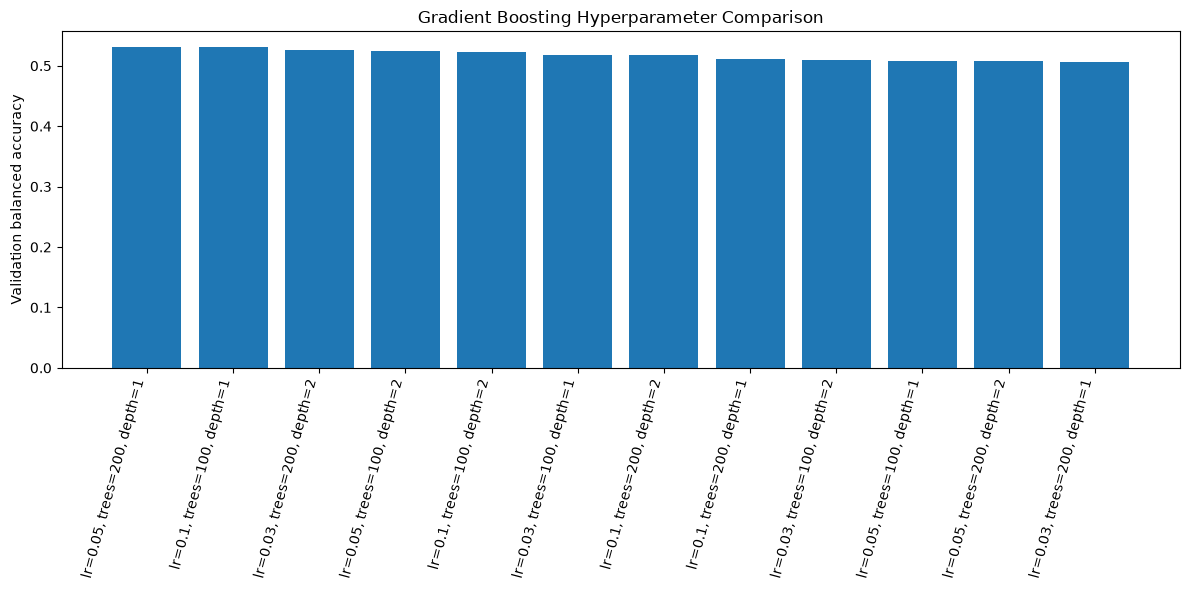

In [12]:
#Visualizing the tuning results
plot_df = tuning_df.copy()

plot_df["label"] = (
    "lr=" + plot_df["learning_rate"].astype(str)
    + ", trees=" + plot_df["n_estimators"].astype(str)
    + ", depth=" + plot_df["max_depth"].astype(str)
)

plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["label"],
    plot_df["val_balanced_accuracy"],
)

plt.xticks(rotation=75, ha="right")
plt.ylabel("Validation balanced accuracy")
plt.title("Gradient Boosting Hyperparameter Comparison")
plt.tight_layout()
plt.show()

In [13]:
#Selecting the best hyperparamers uding validation data
best_row = tuning_df.iloc[0]
best_config = best_row["config"]
best_gb = tuned_models[best_config]

print("Selected configuration:", best_config)
print("Validation balanced accuracy:", round(
    best_row["val_balanced_accuracy"], 4
))
print("Validation macro F1:", round(
    best_row["val_macro_f1"], 4
))
print("Validation log loss:", round(
    best_row["val_log_loss"], 4
))

Selected configuration: lr=0.05, trees=200, depth=1
Validation balanced accuracy: 0.5304
Validation macro F1: 0.5007
Validation log loss: 0.6945


In [14]:
#Examining the selected Model's Training gap
best_train_pred = best_gb.predict(X_train)
best_val_pred = best_gb.predict(X_val)

train_bal_acc = balanced_accuracy_score(
    y_train, best_train_pred
)
val_bal_acc = balanced_accuracy_score(
    y_val, best_val_pred
)

print(f"Training balanced accuracy:   {train_bal_acc:.4f}")
print(f"Validation balanced accuracy: {val_bal_acc:.4f}")
print(f"Train-validation gap:         {train_bal_acc - val_bal_acc:.4f}")

Training balanced accuracy:   0.5648
Validation balanced accuracy: 0.5304
Train-validation gap:         0.0344


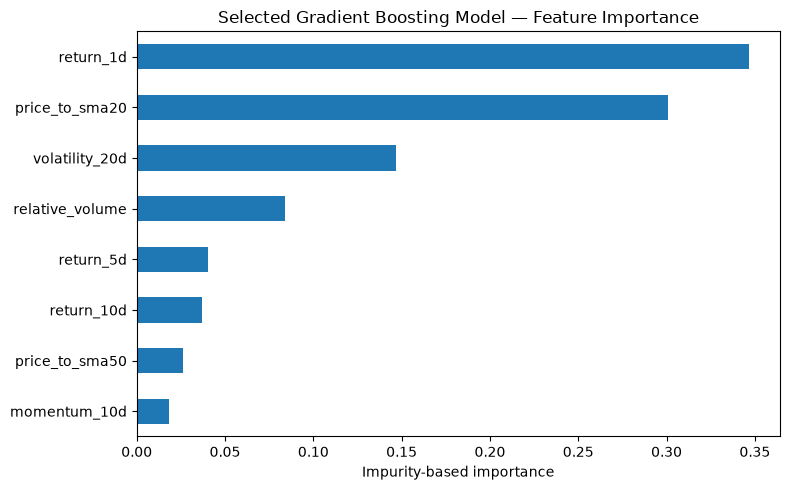

,importance
return_1d,0.346883
price_to_sma20,0.300557
volatility_20d,0.146753
relative_volume,0.083956
return_5d,0.040507
return_10d,0.036968
price_to_sma50,0.026195
momentum_10d,0.018181


In [16]:
#Reviewing feature Importance for the Selected Model
best_importance = pd.Series(
    best_gb.feature_importances_,
    index=FEATURES,
).sort_values(ascending=True)

best_importance.plot(kind="barh", figsize=(8, 5))
plt.title("Selected Gradient Boosting Model — Feature Importance")
plt.xlabel("Impurity-based importance")
plt.tight_layout()
plt.show()

display(
    best_importance.sort_values(ascending=False)
    .to_frame("importance")
)